# House Price Prediction
## Notebook 4 — Model Training and Comparison
**Author: Tinashe Clifford Makandise**

## 1. Objective and selection protocol
Compare a median-price baseline, Linear Regression, Ridge and Random Forest, using the shared factories from Notebook 3. Core and expanded feature sets are compared. A limited log-target Ridge alternative is also included.

Use the same five shuffled folds for every candidate. Select the smallest **mean validation MAE in USD**, with deterministic candidate order breaking exact ties. RMSE, R² and train/validation gaps provide context; they do not override the selection rule. Fold standard deviations describe variability and are not confidence intervals.

These scores are used for model selection and may be optimistic for the chosen winner. The untouched holdout in Notebook 5 provides the final assessment. No claim of future-market or cross-country validity is made.

### Prerequisites
Run Notebooks 1 and 3; keep `src/` in the project root. Save this notebook in `notebooks/`. Install if needed: `%pip install pandas numpy scikit-learn matplotlib joblib`. No data is downloaded here.

In [1]:
from pathlib import Path
import sys, json, hashlib, platform
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import KFold, cross_validate
import joblib
try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value.to_string() if hasattr(value, "to_string") else value)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.modeling import make_model_pipeline
train_path = PROJECT_ROOT / "data/processed/train.csv"
train = pd.read_csv(train_path, keep_default_na=False, na_values=[""])
manifest = json.loads((PROJECT_ROOT / "reports/data_manifest.json").read_text(encoding="utf-8"))
assert len(train) == manifest["train_rows"] and train["PID"].is_unique
assert set(train["PID"].astype(int)) == set(manifest["train_pids"])
assert set(train["PID"].astype(int)).isdisjoint(manifest["test_pids"])
X = train.drop(columns="SalePrice")
y = train["SalePrice"].copy()
assert y.gt(0).all()
REPORTS_DIR = PROJECT_ROOT / "reports"
MODELS_DIR = PROJECT_ROOT / "models"
FIGURES_DIR = REPORTS_DIR / "figures"
for path in [REPORTS_DIR, MODELS_DIR, FIGURES_DIR]:
    path.mkdir(parents=True, exist_ok=True)
folds = list(KFold(n_splits=5, shuffle=True, random_state=42).split(X, y))
scoring = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"}
print(f"Training rows: {len(train):,}; identical five-fold splits prepared. Test file not opened.")

Training rows: 2,344; identical five-fold splits prepared. Test file not opened.


## 2. Candidate models and small hyperparameter search
The baseline learns the median within each fold. Linear models use scaled numeric features; trees do not require scaling. Ridge tests three regularisation strengths. Random Forest tests two minimum leaf sizes with 100 trees and otherwise fixed settings. This is a bounded search rather than exhaustive optimisation.

Core features cover area, bedrooms, full/half bathrooms, age and garage capacity plus neighbourhood. Expanded features add overall quality and condition. The log-target Ridge option transforms prices only inside fitting and returns predictions in USD for scoring. No retransformation correction is assumed. All rows are retained.

Preprocessing remains inside every estimator pipeline: no global encoded matrix or fitted imputer is reused across folds.

In [2]:
candidates = {}
configs = {}
def register(name, estimator, config):
    candidates[name] = estimator
    configs[name] = config
register("Median baseline", DummyRegressor(strategy="median"), {"family": "DummyRegressor", "strategy": "median"})
for expanded in [False, True]:
    label = "expanded" if expanded else "core"
    register(f"Linear | {label}", make_model_pipeline(LinearRegression(), expanded=expanded),
             {"family": "LinearRegression", "expanded": expanded, "scale_numeric": True})
    for alpha in [0.1, 10.0, 100.0]:
        register(f"Ridge a={alpha:g} | {label}", make_model_pipeline(Ridge(alpha=alpha), expanded=expanded),
                 {"family": "Ridge", "alpha": alpha, "expanded": expanded, "scale_numeric": True})
    for leaf in [1, 3]:
        model = RandomForestRegressor(n_estimators=100, min_samples_leaf=leaf, random_state=42, n_jobs=1)
        register(f"Forest leaf={leaf} | {label}", make_model_pipeline(model, expanded=expanded, scale_numeric=False),
                 {"family": "RandomForestRegressor", "n_estimators": 100, "min_samples_leaf": leaf,
                  "expanded": expanded, "scale_numeric": False, "random_state": 42})
    log_ridge = TransformedTargetRegressor(
        regressor=make_model_pipeline(Ridge(alpha=10.0), expanded=expanded),
        func=np.log1p, inverse_func=np.expm1)
    register(f"Log Ridge a=10 | {label}", log_ridge,
             {"family": "Ridge", "alpha": 10.0, "expanded": expanded, "scale_numeric": True, "log_target": True})
print(f"Candidates: {len(candidates)}; CV fits: {len(candidates) * len(folds)}")
display(pd.DataFrame(configs).T.fillna("—"))

Candidates: 15; CV fits: 75
                                          family strategy expanded scale_numeric  alpha n_estimators min_samples_leaf random_state log_target
Median baseline                   DummyRegressor   median        —             —      —            —                —            —          —
Linear | core                   LinearRegression        —    False          True      —            —                —            —          —
Ridge a=0.1 | core                         Ridge        —    False          True    0.1            —                —            —          —
Ridge a=10 | core                          Ridge        —    False          True   10.0            —                —            —          —
Ridge a=100 | core                         Ridge        —    False          True  100.0            —                —            —          —
Forest leaf=1 | core       RandomForestRegressor        —    False         False      —          100                1   

## 3. Run cross-validation
Scikit-learn expresses loss scorers as negative numbers so that higher is better internally. We reverse their signs for readable positive dollar errors. Each candidate is independently cloned and fitted in each fold. `error_score="raise"` prevents a failed model from silently appearing in the comparison. Training metrics are diagnostic only.

In [3]:
rows, fold_rows = [], []
for name, estimator in candidates.items():
    cv_result = cross_validate(estimator, X, y, cv=folds, scoring=scoring,
                               return_train_score=True, n_jobs=1, error_score="raise")
    val_mae = -cv_result["test_mae"]
    train_mae = -cv_result["train_mae"]
    rows.append({"candidate": name, "cv_mae_mean": val_mae.mean(), "cv_mae_std": val_mae.std(ddof=1),
                 "cv_rmse_mean": (-cv_result["test_rmse"]).mean(), "cv_r2_mean": cv_result["test_r2"].mean(),
                 "train_mae_mean": train_mae.mean(), "mae_gap": val_mae.mean()-train_mae.mean()})
    for fold in range(len(folds)):
        fold_rows.append({"candidate": name, "fold": fold+1, "validation_mae": val_mae[fold],
                          "validation_rmse": -cv_result["test_rmse"][fold], "validation_r2": cv_result["test_r2"][fold],
                          "training_mae": train_mae[fold]})
    print(f"{name}: CV MAE ${val_mae.mean():,.0f}")
comparison = pd.DataFrame(rows).sort_values("cv_mae_mean", kind="stable").reset_index(drop=True)
fold_results = pd.DataFrame(fold_rows)
assert np.isfinite(comparison.select_dtypes(include="number")).all().all()
display(comparison.round(3))

Median baseline: CV MAE $54,120
Linear | core: CV MAE $24,397
Ridge a=0.1 | core: CV MAE $24,398
Ridge a=10 | core: CV MAE $24,588
Ridge a=100 | core: CV MAE $26,039
Forest leaf=1 | core: CV MAE $21,237
Forest leaf=3 | core: CV MAE $21,533
Log Ridge a=10 | core: CV MAE $23,004
Linear | expanded: CV MAE $21,284
Ridge a=0.1 | expanded: CV MAE $21,284
Ridge a=10 | expanded: CV MAE $21,570
Ridge a=100 | expanded: CV MAE $22,743
Forest leaf=1 | expanded: CV MAE $19,053
Forest leaf=3 | expanded: CV MAE $19,383
Log Ridge a=10 | expanded: CV MAE $19,181
                    candidate  cv_mae_mean  cv_mae_std  cv_rmse_mean  cv_r2_mean  train_mae_mean    mae_gap
0    Forest leaf=1 | expanded    19052.915     529.376     30260.557       0.844        7071.799  11981.116
1   Log Ridge a=10 | expanded    19181.279     967.136     34607.768       0.782       18859.869    321.410
2    Forest leaf=3 | expanded    19382.581     527.978     31281.043       0.834       11972.725   7409.856
3        Forest 

## 4. Compare errors and generalisation gaps
Lower MAE and RMSE are better; higher R² is better. MAE is an average absolute error, not a prediction interval. RMSE penalises large errors more strongly. Error bars show the standard deviation across the five folds, not statistical significance.

A large training-to-validation gap suggests overfitting. A small gap with poor errors suggests limited fit. Neither diagnostic alone determines the best model.

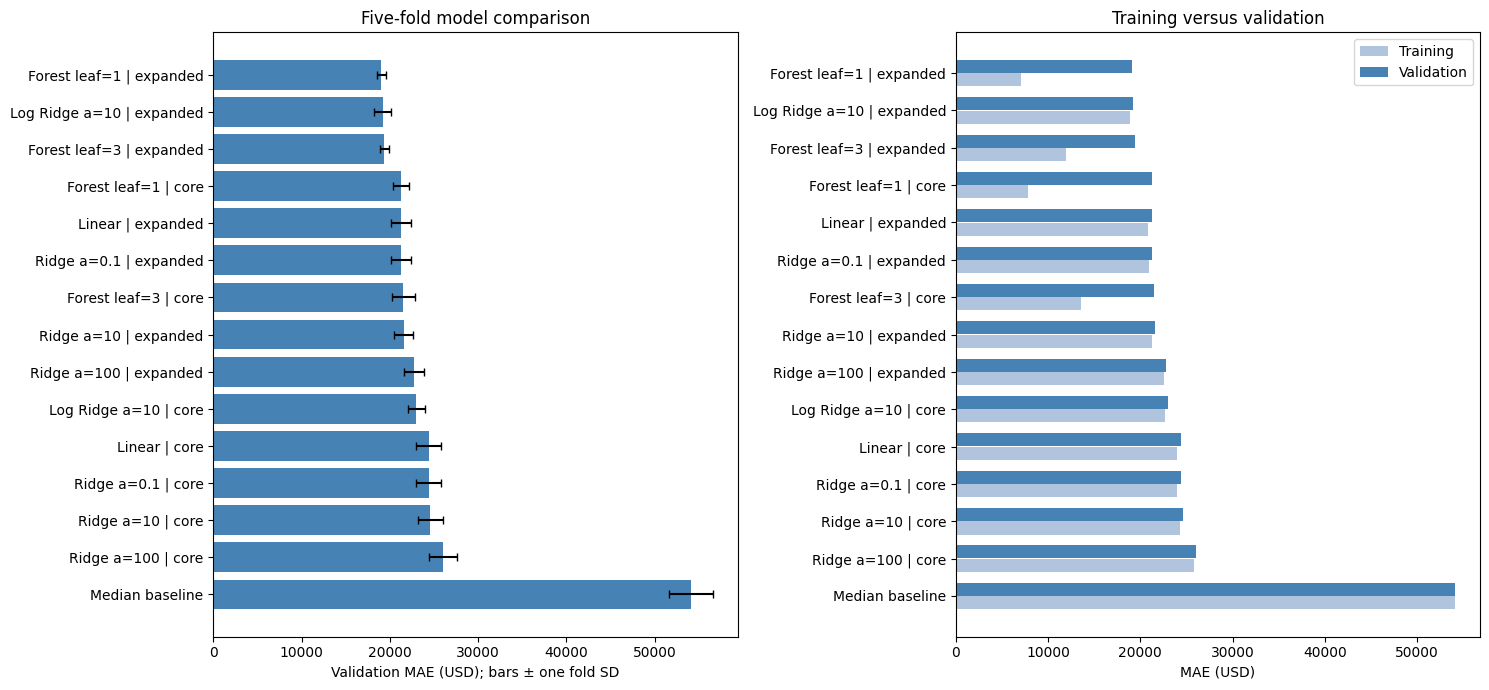

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
plot = comparison.sort_values("cv_mae_mean", ascending=False)
axes[0].barh(plot["candidate"], plot["cv_mae_mean"], xerr=plot["cv_mae_std"], capsize=3, color="steelblue")
axes[0].set(xlabel="Validation MAE (USD); bars ± one fold SD", title="Five-fold model comparison")
positions = np.arange(len(plot))
axes[1].barh(positions-.18, plot["train_mae_mean"], height=.35, label="Training", color="lightsteelblue")
axes[1].barh(positions+.18, plot["cv_mae_mean"], height=.35, label="Validation", color="steelblue")
axes[1].set(yticks=positions, yticklabels=plot["candidate"], xlabel="MAE (USD)", title="Training versus validation")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Freeze the selected configuration
The winner is selected only by mean validation MAE. Comparing many candidates on the same folds introduces selection optimism, so the winning score is not a final test result. Close scores should not be described as definitive superiority.

Save an **unfitted** template and its configuration. Notebook 5 will fit it on the full training partition and evaluate the locked holdout. This template is not a deployable trained model. Keep `src/` with the project when loading it. Only load joblib files produced by a trusted source.

In [5]:
winner_name = comparison.iloc[0]["candidate"]
winner_template = clone(candidates[winner_name])
baseline_mae = comparison.set_index("candidate").loc["Median baseline", "cv_mae_mean"]
winner_mae = float(comparison.iloc[0]["cv_mae_mean"])
improvement = 100 * (baseline_mae - winner_mae) / baseline_mae
selection = {
    "author": "Tinashe Clifford Makandise", "candidate": winner_name, "configuration": configs[winner_name],
    "selection_metric": "mean five-fold validation MAE in USD", "cv_mae": winner_mae,
    "cv_rmse": float(comparison.iloc[0]["cv_rmse_mean"]), "cv_r2": float(comparison.iloc[0]["cv_r2_mean"]),
    "baseline_cv_mae": float(baseline_mae), "improvement_vs_baseline_percent": float(improvement),
    "cv": {"n_splits": 5, "shuffle": True, "random_state": 42}, "test_data_used": False,
    "artifact_state": "unfitted template; fit on training data before prediction",
    "train_sha256": hashlib.sha256(train_path.read_bytes()).hexdigest(),
    "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__},
}
comparison.to_csv(REPORTS_DIR / "model_comparison.csv", index=False)
fold_results.to_csv(REPORTS_DIR / "cv_fold_results.csv", index=False)
(REPORTS_DIR / "selected_model_config.json").write_text(json.dumps(selection, indent=2), encoding="utf-8")
joblib.dump(winner_template, MODELS_DIR / "selected_model_template.joblib")
loaded_template = joblib.load(MODELS_DIR / "selected_model_template.joblib")
assert type(loaded_template) is type(winner_template)
print(f"Selected: {winner_name}")
print(f"Cross-validation MAE: ${winner_mae:,.0f}; improvement over baseline: {improvement:.1f}%")
print("Unfitted template saved and reloaded successfully. No holdout results produced.")

Selected: Forest leaf=1 | expanded
Cross-validation MAE: $19,053; improvement over baseline: 64.8%
Unfitted template saved and reloaded successfully. No holdout results produced.


## 6. Handover to final evaluation
**Files produced:**
- `reports/model_comparison.csv`: aggregate cross-validation metrics.
- `reports/cv_fold_results.csv`: individual fold results.
- `reports/selected_model_config.json`: frozen configuration and provenance.
- `models/selected_model_template.joblib`: unfitted selected estimator.
- `reports/figures/04_model_comparison.png`: comparison chart.

**Notebook 5:** verify partition identity, fit the selected template on the full training partition, predict the held-out test properties, evaluate MAE/RMSE/R² and residuals, compare with a training-fitted median baseline, and export the fitted pipeline with metadata. Explain error patterns without tuning the model against test results.

Do not label cross-validation scores as final accuracy, interpret R² as a percentage of predictions correct, or represent MAE as per-property confidence. Performance applies to historical Ames housing under this evaluation design.